In [4]:
#constants and imports

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t


nu = 5
mu = 1
sigma = 0.01
n = 700



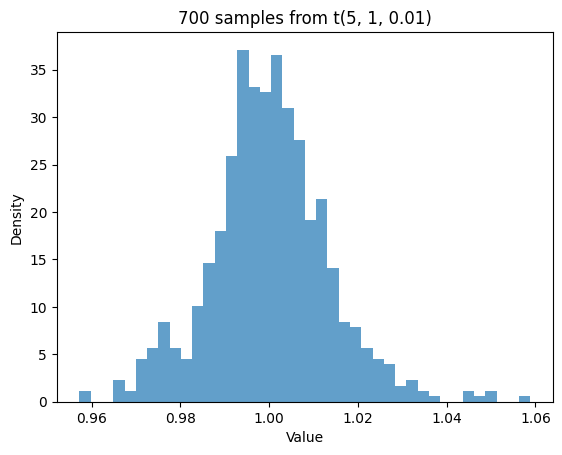

In [ ]:
#t-distribution

np.random.seed(37)
samples = t.rvs(df=nu, loc=mu, scale=sigma, size=n)

#plot showing first 700 examples

plt.hist(samples, bins=40, density=True, alpha=0.7)
plt.xlabel("Value")
plt.ylabel("Density")
plt.title("700 samples from t(5, 1, 0.01)")
plt.show()


In [74]:
p = 0.975
q = 0.95
#Exact quantile from distribtuion
sorted_samples = np.sort(samples)
theta_obs = np.quantile(sorted_samples, p, method="inverted_cdf")
print("Empirical quantile:", theta_obs)

theta_true = t.ppf(p, df=5, loc=1, scale=0.01)
print("True quantile:", theta_true)






bootstrap_sample = np.random.choice(samples, size=700, replace=True)

theta_star = np.quantile(bootstrap_sample, 0.975, method="inverted_cdf")
print("star quantile:", theta_star)

residual = theta_obs - theta_star


lower = theta_obs + residual
upper = theta_obs + residual

print(lower)
print(upper)

Empirical quantile: 1.0279383108492777
True quantile: 1.0257058183563632
star quantile: 1.0250868641505742
1.0307897575479812
1.0307897575479812


In [82]:
res_list= []
for k in range(200):
    bootstrap_sample = np.random.choice(samples, size=700, replace=True)
    theta_star = np.quantile(bootstrap_sample, 0.975, method="inverted_cdf")

    res_list.append(theta_obs - theta_star)

residuals = np.sort(res_list)[::-1]

lower = theta_obs + residuals[195]
upper = theta_obs + residuals[5]

print(lower)
print(upper)


plt.figure(figsize=(10, 9))

for i in range(k):
    color = "blue" if contains[i] else "red"
    plt.plot([lower_list[i], upper_list[i]], [i+1, i+1], color=color)

plt.axvline(theta_true, color="black", linestyle="--", label="True quantile")

plt.xlabel("Quantile value")
plt.ylabel("Confidence interval number")
plt.title("200 Bootstrap Confidence Intervals (95%)")
plt.legend()
plt.show()

1.022571314195597
1.0311893629531077


NameError: name 'contains' is not defined

<Figure size 1000x900 with 0 Axes>